In [1]:
# LSTM and GRU - fixing the memory problem of plain RNNs
# Dataset: SMS Spam Collection - ../Datasets/spam.csv
#
# Needs: pip install tensorflow
#
# THE IDEA
# A plain RNN rewrites its whole memory at every step, so old information fades fast.
# LSTM and GRU add GATES - small learned switches (numbers between 0 and 1) that decide
# what to keep, what to forget and what to let through.
#
#   LSTM (Long Short-Term Memory) - two memories and three gates:
#       forget gate : how much of the old memory to throw away
#       input gate  : how much of the new information to store
#       output gate : how much of the memory to reveal as this step's output
#       cell state  : a separate long-term "conveyor belt" that information can ride along
#                     almost untouched. This is what stops the gradient from vanishing.
#
#   GRU (Gated Recurrent Unit) - a simpler cousin, one memory and two gates:
#       update gate : how much of the old memory to keep vs replace
#       reset gate  : how much of the old memory to use when forming new information
#       fewer gates = fewer parameters = faster, often nearly as accurate as LSTM
#
# This script trains all of them on the same data, so you can compare them directly.

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)

C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/

In [2]:
# ---- 1. Load and split (same preparation as script 47) ----
df = pd.read_csv("../Datasets/spam.csv", encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"].values, df["label_num"].values,
    test_size=0.2, random_state=42, stratify=df["label_num"]
)

MAX_WORDS = 5000
SEQ_LEN = 40

vectorizer = layers.TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=SEQ_LEN)
vectorizer.adapt(X_train_text)

X_train = vectorizer(X_train_text).numpy()
X_test = vectorizer(X_test_text).numpy()

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

In [3]:
# ---- 2. Parameter count: what do the gates cost? ----
# the recurrent layer needs (input_size + units + 1) * units weights PER gate-block:
#   SimpleRNN = 1 block, GRU = 3 blocks, LSTM = 4 blocks
# (Keras's GRU uses a slightly different bias layout, so its count is a bit above 3x)
for name, layer_class in [("SimpleRNN", layers.SimpleRNN), ("GRU", layers.GRU), ("LSTM", layers.LSTM)]:
    test_model = keras.Sequential([
        layers.Input(shape=(SEQ_LEN, 32)),
        layer_class(32)
    ])
    print(f"{name:10s} layer parameters: {test_model.count_params():,}")



SimpleRNN  layer parameters: 2,080
GRU        layer parameters: 6,336
LSTM       layer parameters: 8,320


In [4]:
# ---- 3. Four models that differ ONLY in the recurrent layer ----
architectures = {
    "SimpleRNN": layers.SimpleRNN(32),
    "GRU": layers.GRU(32),
    "LSTM": layers.LSTM(32),
    "Bidirectional LSTM": layers.Bidirectional(layers.LSTM(32)),
}
# Bidirectional = two LSTMs, one reading left-to-right and one right-to-left, results joined.
# Each word then gets context from BOTH before and after it.

results = []
histories = {}

for name, recurrent_layer in architectures.items():
    tf.random.set_seed(42)          # same starting point for a fair comparison

    # build a fresh copy of the recurrent layer from its config (layers can't be reused)
    new_layer = recurrent_layer.__class__.from_config(recurrent_layer.get_config())

    model = keras.Sequential([
        layers.Input(shape=(SEQ_LEN,)),
        layers.Embedding(MAX_WORDS, 32),
        new_layer,
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_split=0.1, epochs=10, batch_size=32,
        class_weight=class_weight, verbose=0
       )
    train_seconds = time.time() - start

    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob > 0.5).astype(int)

    results.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Train time (s)": round(train_seconds, 1),
        "Spam precision": round(precision_score(y_test, y_pred), 3),
        "Spam recall": round(recall_score(y_test, y_pred), 3),
        "Spam F1": round(f1_score(y_test, y_pred), 3),
    })
    histories[name] = history.history

    print(f"finished {name}")

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


finished SimpleRNN
finished GRU
finished LSTM
finished Bidirectional LSTM
             Model  Parameters  Train time (s)  Spam precision  Spam recall  Spam F1
         SimpleRNN      162113            13.5           0.943        0.886    0.913
               GRU      166369            24.7           0.887        0.953    0.919
              LSTM      168353            22.9           0.939        0.926    0.932
Bidirectional LSTM      176705            27.8           0.985        0.899    0.940


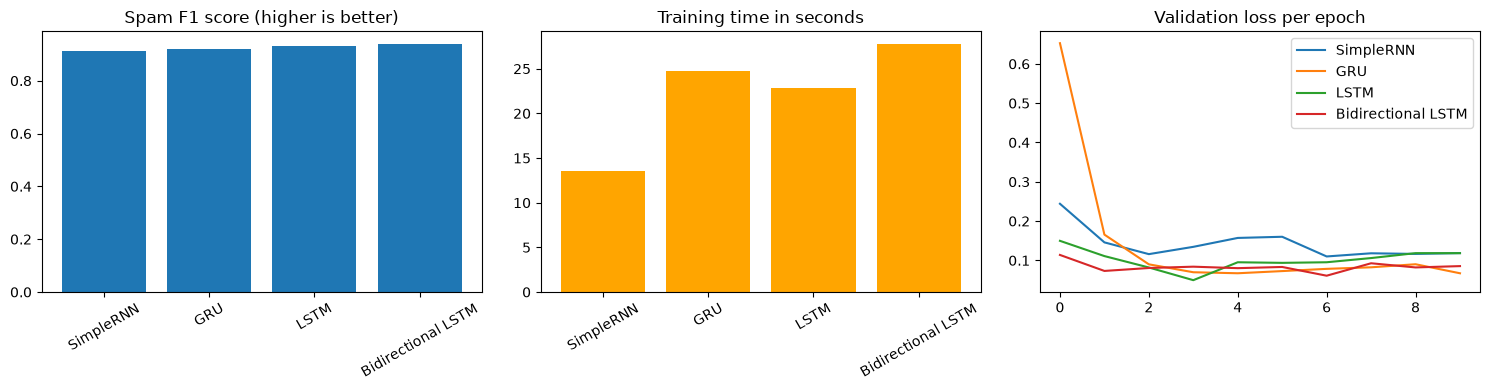

In [5]:
# ---- 4. Compare visually ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(results_df["Model"], results_df["Spam F1"])
axes[0].set_title("Spam F1 score (higher is better)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(results_df["Model"], results_df["Train time (s)"], color="orange")
axes[1].set_title("Training time in seconds")
axes[1].tick_params(axis="x", rotation=30)

for name, hist in histories.items():
    axes[2].plot(hist["val_loss"], label=name)
axes[2].set_title("Validation loss per epoch")
axes[2].legend()

plt.tight_layout()
plt.show()

# WHAT TO EXPECT
#   - On short SMS texts all four may score similarly - the sequences are short enough
#     that even a plain RNN can cope. The gap opens up on LONGER text.
#   - GRU has fewer parameters than LSTM and is usually a bit faster for similar accuracy.
#     On a dataset this small the timings are noisy, so don't read much into one run.
#   - Bidirectional LSTM costs about double and often gives a small accuracy gain.
#   - Rule of thumb: try GRU first (cheap), switch to LSTM if the sequences are long and
#     accuracy matters more than speed. Both are now often replaced by Transformers (script 49).